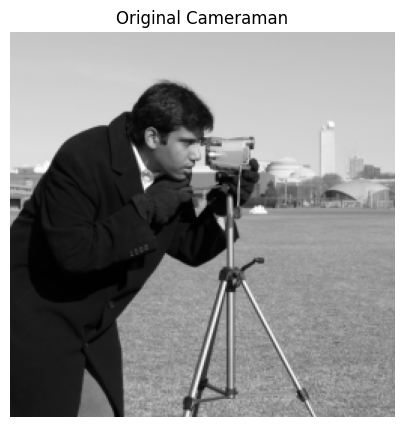

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from numpy.fft import fft2, ifft2, ifftshift, fftshift

# Load the grayscale Cameraman image and resize it
image = resize(data.camera(), (256, 256), anti_aliasing=True)

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title("Original Cameraman")
plt.axis("off")
plt.show()

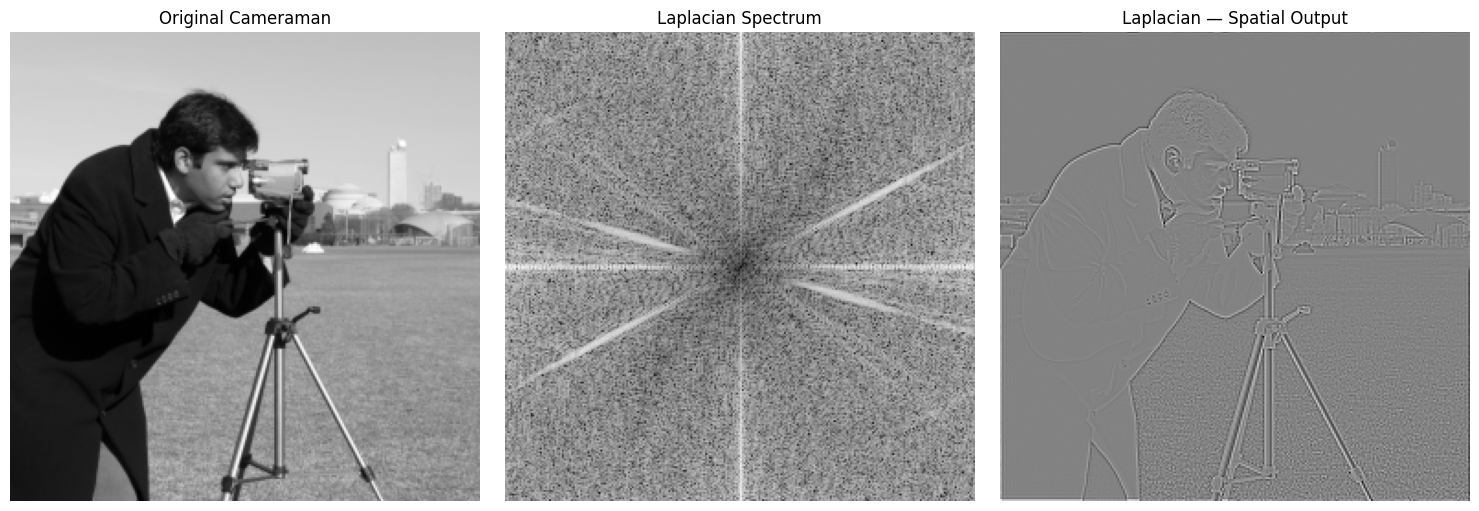

In [2]:
M, N = image.shape

u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)


F = fft2(image)
F_lap = F * laplacian_filter

laplacian_image = ifft2(F_lap).real

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image, cmap="gray")
ax[0].set_title("Original Cameraman")

ax[1].imshow(
    np.log1p(np.abs(fftshift(F_lap))),
    cmap="gray"
)
ax[1].set_title("Laplacian Spectrum")

ax[2].imshow(laplacian_image, cmap="gray")
ax[2].set_title("Laplacian — Spatial Output")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

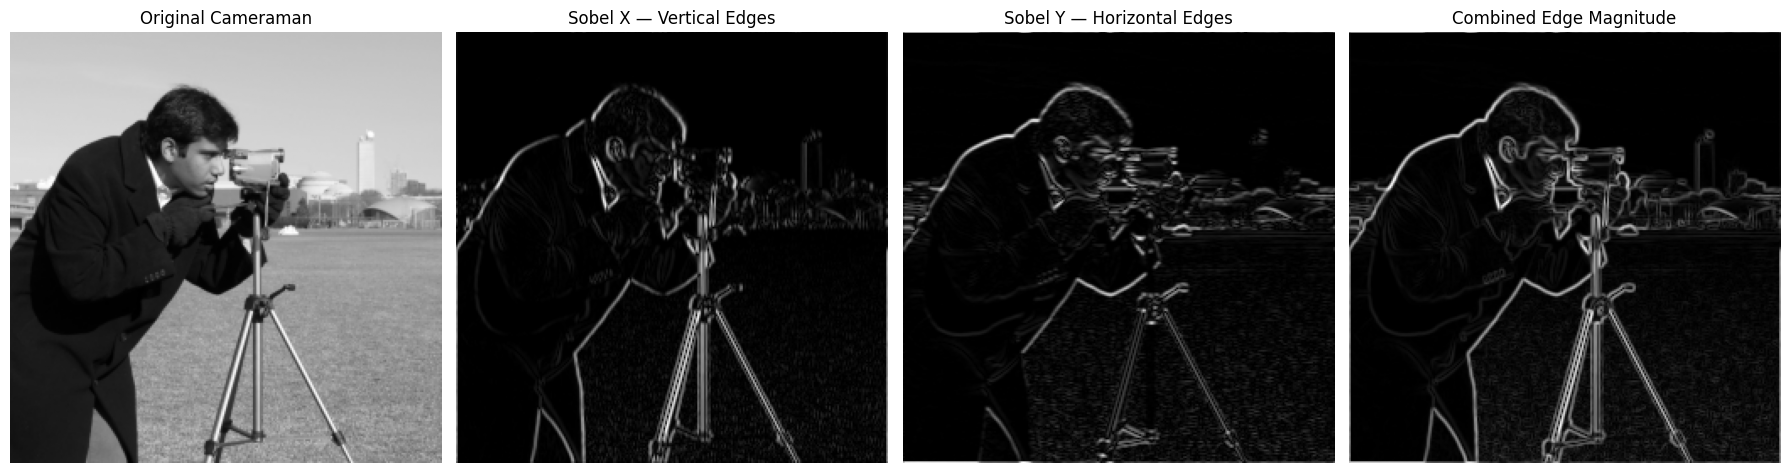

In [3]:
# Sobel kernels
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

# Pad and center each kernel, then transform it
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    cy, cx = shape[0] // 2, shape[1] // 2

    padded[
        cy - kh // 2:cy - kh // 2 + kh,
        cx - kw // 2:cx - kw // 2 + kw
    ] = kernel

    return fft2(ifftshift(padded))

# FFT of the image and kernels
F = fft2(image)
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain, then inverse FFT
edges_x = ifft2(F * H_x).real
edges_y = ifft2(F * H_y).real

# Combine both directional responses
edge_magnitude = np.hypot(edges_x, edges_y)

# Display edge strengths
results = [
    image,
    np.abs(edges_x),
    np.abs(edges_y),
    edge_magnitude
]

titles = [
    "Original Cameraman",
    "Sobel X — Vertical Edges",
    "Sobel Y — Horizontal Edges",
    "Combined Edge Magnitude"
]

fig, ax = plt.subplots(1, 4, figsize=(18, 5))

for a, result, title in zip(ax, results, titles):
    a.imshow(result, cmap="gray")
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()